
# Alabama County-Scale ECMWF S2S Soil-Moisture Calibration and Prediction

**Experimental prototype for all 67 Alabama counties**

This version extends the statewide prototype to produce a separate calibrated forecast for every Alabama county.

## Workflow

1. Download ECMWF S2S real-time `sm100` or `sm20` forecasts.
2. Download the matching 20-year ECMWF on-the-fly reforecasts.
3. Read ERA5-Land soil moisture from ECMWF ARCO.
4. Obtain official U.S. Census county polygons and retain Alabama's 67 counties.
5. Calculate **fractional grid-cell overlap weights** for each county.
6. Calculate county means separately for:
   - the native 1.5° S2S grid;
   - the 0.1° ERA5-Land grid.
7. Aggregate to Week 1, Week 2, Week 3–4, and Week 5–6.
8. Fit **a separate empirical quantile mapping calibration for every county and lead period**.
9. Perform leave-one-year-out (LOYO) validation independently for every county.
10. Produce county-level calibrated ensemble statistics and:
    \[
    P(SM < P20)
    \]
11. Save CSV tables, GeoJSON maps, and county forecast figures.

## Critical resolution caveat

The public S2S archive is approximately **1.5°**, much coarser than an Alabama county.  
This notebook **does not interpolate S2S soil moisture to a finer grid**, because that would create artificial spatial detail.

Instead, each county forecast is the area-weighted average of the *native S2S grid cells that overlap that county*. Consequently:

- neighboring counties may have highly similar or identical raw S2S forecasts;
- county-specific calibration can correct county climatology/bias;
- it **cannot create true county-scale meteorological predictability that is absent from the coarse model grid**.

The notebook therefore also reports the number of native S2S grid cells supporting each county and the fraction contributed by the dominant grid cell.



## 0. Installation

```bash
pip install cdsapi xarray pandas numpy scipy matplotlib geopandas shapely pyproj \
            requests zarr fsspec cfgrib eccodes
```

For `cfgrib/eccodes`, conda is often more reliable:

```bash
conda install -c conda-forge cfgrib eccodes geopandas shapely pyproj xarray zarr
pip install cdsapi
```

You need:

- an **ECMWF Data Store (ECDS)** token for S2S data;
- a **Copernicus CDS** token for ERA5-Land ARCO access.


In [1]:
!pip install cdsapi xarray pandas numpy scipy matplotlib geopandas shapely pyproj requests zarr fsspec cfgrib eccodes

Defaulting to user installation because normal site-packages is not writeable


In [2]:
from pathlib import Path
from getpass import getpass
import os
import warnings

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from IPython.display import display

import cdsapi
import requests
import geopandas as gpd

from shapely.geometry import box
from shapely.ops import transform as shp_transform
from pyproj import Transformer

warnings.filterwarnings("ignore")

# ============================================================
# USER SETTINGS
# ============================================================

# Choose an ECMWF S2S model-version date for which an on-the-fly
# reforecast set is available. Current sub-seasonal reforecasts
# are available for odd calendar days (excluding Feb 29).
MODEL_DATE = "2026-08-23"

# Recommended first experiment: top 100 cm root-zone soil moisture.
# Change to "sm20" to repeat for top 20 cm.
TARGET = "sm100"

PERIODS = {
    "Week 1": (1, 7),
    "Week 2": (8, 14),
    "Week 3-4": (15, 28),
    "Week 5-6": (29, 42),
}

# Slightly buffered Alabama box: [North, West, South, East]
AL_DOWNLOAD_BOX = [36.0, -90.0, 29.0, -84.0]

# "all" = all 67 counties.
# For a quick code test, use e.g. ["Lee", "Macon", "Montgomery"].
COUNTIES_TO_RUN = "all"

if COUNTIES_TO_RUN == "all":
    COUNTY_TAG = "all67"
else:
    COUNTY_TAG = "subset_" + "_".join(
        str(x).replace(" ", "")
        for x in COUNTIES_TO_RUN
    )

ROOT = Path("alabama_county_s2s_experiment")
RAW = ROOT / "raw"
OUT = ROOT / "output"
RAW.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)

MODEL_DATE = pd.Timestamp(MODEL_DATE)
HINDCAST_YEARS = list(range(MODEL_DATE.year - 20, MODEL_DATE.year))
LEAD_HOURS = [str(24 * d) for d in range(1, 43)]

S2S_VARIABLE = {
    "sm100": "soil_moisture_top_100_cm",
    "sm20": "soil_moisture_top_20_cm",
}[TARGET]

print("Model date:", MODEL_DATE.date())
print("Target:", TARGET)
print("Hindcast years:", HINDCAST_YEARS[0], "to", HINDCAST_YEARS[-1])


Model date: 2026-08-23
Target: sm100
Hindcast years: 2006 to 2025



## 1. Authentication


In [3]:

ECDS_KEY = os.getenv("ECDS_KEY")
if not ECDS_KEY:
    ECDS_KEY = getpass("Paste your ECMWF Data Store (ECDS) token: ")

CDS_KEY = os.getenv("CDS_KEY")
if not CDS_KEY:
    CDS_KEY = getpass("Paste your Copernicus CDS token: ")

ecds = cdsapi.Client(
    url="https://ecds.ecmwf.int/api",
    key=ECDS_KEY
)

print("ECDS/CDS credentials configured.")


Paste your ECMWF Data Store (ECDS) token:  ········
Paste your Copernicus CDS token:  ········


ECDS/CDS credentials configured.



## 2. Alabama county polygons

This uses the U.S. Census Bureau 2025 1:500,000 national county cartographic boundary file
and filters it to Alabama (`STATEFP = "01"`).


In [4]:

CENSUS_COUNTY_URL = (
    "https://www2.census.gov/geo/tiger/GENZ2025/shp/"
    "cb_2025_us_county_500k.zip"
)
county_zip = RAW / "cb_2025_us_county_500k.zip"

if not county_zip.exists():
    r = requests.get(CENSUS_COUNTY_URL, timeout=180)
    r.raise_for_status()
    county_zip.write_bytes(r.content)

counties = gpd.read_file(f"zip://{county_zip.resolve()}")
counties = counties.loc[counties["STATEFP"] == "01"].copy()
counties = counties.to_crs("EPSG:4326")
counties = counties.sort_values("NAME").reset_index(drop=True)

counties = counties.rename(
    columns={
        "GEOID": "county_fips",
        "NAME": "county_name",
    }
)

if COUNTIES_TO_RUN != "all":
    counties = counties.loc[
        counties["county_name"].isin(COUNTIES_TO_RUN)
    ].copy().reset_index(drop=True)

if COUNTIES_TO_RUN == "all" and len(counties) != 67:
    raise RuntimeError(
        f"Expected 67 Alabama counties, found {len(counties)}."
    )

print("Counties selected:", len(counties))
display(counties[["county_fips", "county_name"]].head())


Counties selected: 67


,county_fips,county_name
0,01001,Autauga
1,01003,Baldwin
2,01005,Barbour
3,01007,Bibb
4,01009,Blount



## 3. Generic county-overlap weighting

For each grid, the code determines the actual area of intersection between every grid cell
and each county in an equal-area projection (EPSG:5070).

This produces physically meaningful area weights rather than simply assigning counties to
the nearest grid-cell center.


In [5]:

def _edges_from_centers(values):
    values = np.asarray(values, dtype=float)

    if values.size < 2:
        raise ValueError("At least two grid centers are required.")

    if np.any(np.diff(values) <= 0):
        raise ValueError("Grid centers must be strictly increasing.")

    mids = 0.5 * (values[:-1] + values[1:])
    first = values[0] - 0.5 * (values[1] - values[0])
    last = values[-1] + 0.5 * (values[-1] - values[-2])

    return np.concatenate([[first], mids, [last]])


def standardize_latlon(obj):
    # Rename coordinate conventions if necessary.
    rename = {}

    if "lat" in obj.coords and "latitude" not in obj.coords:
        rename["lat"] = "latitude"

    if "lon" in obj.coords and "longitude" not in obj.coords:
        rename["lon"] = "longitude"

    if rename:
        obj = obj.rename(rename)

    # Convert longitudes from 0..360 to -180..180.
    if "longitude" in obj.coords:
        lon = (((obj.longitude + 180) % 360) - 180)
        obj = obj.assign_coords(longitude=lon).sortby("longitude")

    if "latitude" in obj.coords:
        obj = obj.sortby("latitude")

    return obj


def county_overlap_weights(latitudes, longitudes, county_gdf):
    """
    Calculate actual county-grid overlap areas in m2.

    Returns an xarray DataArray:
        county x latitude x longitude

    The county coordinate contains the Census GEOID/FIPS.
    """

    latitudes = np.asarray(latitudes, dtype=float)
    longitudes = np.asarray(longitudes, dtype=float)

    lat_edges = _edges_from_centers(latitudes)
    lon_edges = _edges_from_centers(longitudes)

    transformer = Transformer.from_crs(
        "EPSG:4326",
        "EPSG:5070",
        always_xy=True
    ).transform

    county_proj = county_gdf.to_crs("EPSG:5070")
    county_bounds = county_gdf.geometry.bounds.to_numpy()

    weights = np.zeros(
        (len(county_gdf), len(latitudes), len(longitudes)),
        dtype=np.float64
    )

    for i in range(len(latitudes)):
        cell_south = lat_edges[i]
        cell_north = lat_edges[i + 1]

        for j in range(len(longitudes)):
            cell_west = lon_edges[j]
            cell_east = lon_edges[j + 1]

            # Fast bounding-box candidate test in lon/lat.
            candidate = np.where(
                (county_bounds[:, 0] < cell_east) &
                (county_bounds[:, 2] > cell_west) &
                (county_bounds[:, 1] < cell_north) &
                (county_bounds[:, 3] > cell_south)
            )[0]

            if len(candidate) == 0:
                continue

            cell_geo = box(
                cell_west,
                cell_south,
                cell_east,
                cell_north
            )
            cell_proj = shp_transform(transformer, cell_geo)

            for k in candidate:
                overlap = cell_proj.intersection(
                    county_proj.geometry.iloc[k]
                )

                if not overlap.is_empty:
                    weights[k, i, j] = overlap.area

    da = xr.DataArray(
        weights,
        dims=("county", "latitude", "longitude"),
        coords={
            "county": county_gdf["county_fips"].astype(str).values,
            "county_name": (
                "county",
                county_gdf["county_name"].astype(str).values
            ),
            "latitude": latitudes,
            "longitude": longitudes,
        },
        name="county_overlap_area"
    )

    da.attrs["units"] = "m2"
    return da


def county_area_mean(da, weights):
    """
    Area-weighted mean for every county.

    The calculation is done one county at a time to avoid creating a very
    large county x time x grid temporary array for ERA5-Land.
    """

    da = standardize_latlon(da)

    w_all = weights.sel(
        latitude=da.latitude,
        longitude=da.longitude
    )

    results = []

    for county_id in w_all.county.values:
        w = w_all.sel(county=county_id)

        # Account for any missing land values.
        numerator = (da * w).sum(
            ("latitude", "longitude"),
            skipna=True
        )

        valid_weight = w.where(da.notnull())
        denominator = valid_weight.sum(
            ("latitude", "longitude"),
            skipna=True
        )

        county_mean = numerator / denominator
        county_mean = county_mean.expand_dims(
            county=[county_id]
        )

        results.append(county_mean)

    out = xr.concat(results, dim="county")

    name_lookup = dict(
        zip(
            weights.county.values,
            weights.county_name.values
        )
    )

    out = out.assign_coords(
        county_name=(
            "county",
            [name_lookup[c] for c in out.county.values]
        )
    )

    return out


def county_grid_support(weights):
    """
    Diagnose how much native-grid information supports each county.

    effective_cells = (sum w)^2 / sum(w^2)
    dominant_cell_fraction = max(w) / sum(w)
    """

    rows = []

    for county_id in weights.county.values:
        w = weights.sel(county=county_id).values
        positive = w[w > 0]

        total = positive.sum()

        if len(positive) == 0 or total == 0:
            n_cells = 0
            effective = np.nan
            dominant = np.nan
            area_km2 = np.nan

        else:
            n_cells = len(positive)
            effective = total**2 / np.sum(positive**2)
            dominant = positive.max() / total
            area_km2 = total / 1.0e6

        county_name = str(
            weights.county_name.sel(county=county_id).values
        )

        rows.append({
            "county_fips": str(county_id),
            "county_name": county_name,
            "overlap_area_km2": area_km2,
            "n_native_grid_cells": n_cells,
            "effective_grid_cells": effective,
            "dominant_cell_fraction": dominant,
        })

    support = pd.DataFrame(rows)

    support["resolution_note"] = np.where(
        support["dominant_cell_fraction"] >= 0.80,
        ">=80% of county forecast comes from one S2S grid cell",
        "county forecast combines multiple S2S grid cells"
    )

    return support



## 4. Download ECMWF S2S real-time forecast


In [6]:

def download_s2s_realtime(model_date, target=TARGET):
    model_date = pd.Timestamp(model_date)

    common = {
        "origin": "ecmwf",
        "level_type": "single_level",
        "variable": [S2S_VARIABLE],
        "year": str(model_date.year),
        "month": f"{model_date.month:02d}",
        "day": f"{model_date.day:02d}",
        "leadtime_hour": LEAD_HOURS,
        "time": "00:00",
        "area": AL_DOWNLOAD_BOX,
        "grid": "1.5/1.5",
        "data_format": "grib",
    }

    files = {}

    for forecast_type, short in [
        ("control_forecast", "cf"),
        ("perturbed_forecast", "pf"),
    ]:
        target_file = RAW / (
            f"ecmwf_s2s_rt_{target}_{model_date:%Y%m%d}_{short}.grib"
        )

        if not target_file.exists():
            request = common | {
                "forecast_type": forecast_type
            }

            ecds.retrieve(
                "s2s-forecasts",
                request,
                str(target_file)
            )

        files[short] = target_file

    return files



## 5. Download the matching 20-year ECMWF S2S reforecasts


In [7]:

def download_s2s_reforecasts(model_date, target=TARGET):
    model_date = pd.Timestamp(model_date)

    hyears = [
        str(y)
        for y in range(
            model_date.year - 20,
            model_date.year
        )
    ]

    common = {
        "origin": "ecmwf",
        "level_type": "single_level",
        "variable": [S2S_VARIABLE],

        # Associated/model-version date
        "year": str(model_date.year),
        "month": f"{model_date.month:02d}",
        "day": f"{model_date.day:02d}",

        # Actual historical initialization dates
        "hyear": hyears,
        "hmonth": [f"{model_date.month:02d}"],
        "hday": [f"{model_date.day:02d}"],

        "leadtime_hour": LEAD_HOURS,
        "time": "00:00",
        "area": AL_DOWNLOAD_BOX,
        "grid": "1.5/1.5",
        "data_format": "grib",
    }

    files = {}

    for forecast_type, short in [
        ("control_forecast", "cf"),
        ("perturbed_forecast", "pf"),
    ]:
        target_file = RAW / (
            f"ecmwf_s2s_rf_{target}_{model_date:%Y%m%d}_{short}.grib"
        )

        if not target_file.exists():
            request = common | {
                "forecast_type": forecast_type
            }

            ecds.retrieve(
                "s2s-reforecasts",
                request,
                str(target_file)
            )

        files[short] = target_file

    return files



## 6. Read S2S GRIB and form control + perturbed ensemble


In [8]:

def open_s2s_grib(path):
    ds = xr.open_dataset(
        path,
        engine="cfgrib",
        backend_kwargs={"indexpath": ""}
    )

    ds = standardize_latlon(ds)

    candidates = [
        "sm100",
        "sm20",
        S2S_VARIABLE
    ]

    found = [
        v for v in candidates
        if v in ds.data_vars
    ]

    if found:
        var = found[0]
    elif len(ds.data_vars) == 1:
        var = list(ds.data_vars)[0]
    else:
        raise KeyError(
            f"Could not identify soil moisture in {path}. "
            f"Variables: {list(ds.data_vars)}"
        )

    da = ds[var].astype("float64")

    # S2S sm20/sm100 may be represented in kg m-3.
    # Convert to the familiar volumetric m3 m-3 if needed.
    sample_max = float(da.max(skipna=True).values)

    if sample_max > 2.0:
        da = da / 1000.0

    da.attrs["units"] = "m3 m-3"
    return da


def add_member_dimension(control, perturbed):
    member_name = (
        "number"
        if "number" in perturbed.dims
        else "member"
    )

    if member_name != "member":
        perturbed = perturbed.rename(
            {member_name: "member"}
        )

    if "member" not in control.dims:
        control = control.expand_dims(member=[0])
    elif member_name != "member":
        control = control.rename(
            {member_name: "member"}
        )

    if "member" not in perturbed.coords:
        perturbed = perturbed.assign_coords(
            member=np.arange(
                1,
                perturbed.sizes["member"] + 1
            )
        )

    if 0 in np.asarray(perturbed.member.values):
        perturbed = perturbed.assign_coords(
            member=np.arange(
                1,
                perturbed.sizes["member"] + 1
            )
        )

    return xr.concat(
        [control, perturbed],
        dim="member"
    ).sortby("member")


def add_lead_day(da):
    if "step" not in da.coords and "step" not in da.dims:
        raise KeyError("Expected a 'step' coordinate or dimension in S2S GRIB.")

    # Ensure step is a dimension, not just a scalar coordinate
    if "step" not in da.dims:
        da = da.expand_dims("step")

    step = da["step"]

    if np.issubdtype(step.dtype, np.timedelta64):
        lead_day = (step / np.timedelta64(1, "D")).astype(int)
    else:
        lead_day = (step.astype(float) / 24.0).round().astype(int)

    return da.assign_coords(lead_day=("step", np.atleast_1d(lead_day.values)))


def load_s2s_ensemble(files):
    cf = open_s2s_grib(files["cf"])
    pf = open_s2s_grib(files["pf"])

    da = add_member_dimension(cf, pf)
    da = add_lead_day(da)

    return da



## 7. Convert native S2S forecasts to county-scale area means

No interpolation is performed.

For county \(c\):

\[
SM_c =
\frac{\sum_i A_{ic} SM_i}
     {\sum_i A_{ic}}
\]

where \(A_{ic}\) is the actual part of S2S grid cell \(i\) lying inside county \(c\).


In [9]:

def weekly_period_means(county_daily):
    pieces = []
    labels = []

    for label, (d1, d2) in PERIODS.items():
        sub = county_daily.where(
            (county_daily.lead_day >= d1) &
            (county_daily.lead_day <= d2),
            drop=True
        )

        pieces.append(
            sub.mean("step")
        )
        labels.append(label)

    out = xr.concat(
        pieces,
        dim="period"
    )

    return out.assign_coords(
        period=labels
    )


def s2s_county_weekly(ensemble_da, county_gdf):
    ensemble_da = standardize_latlon(
        ensemble_da
    )

    weights = county_overlap_weights(
        ensemble_da.latitude.values,
        ensemble_da.longitude.values,
        county_gdf
    )

    county_daily = county_area_mean(
        ensemble_da,
        weights
    )

    county_weekly = weekly_period_means(
        county_daily
    )

    support = county_grid_support(weights)

    return (
        county_daily,
        county_weekly,
        weights,
        support
    )



## 8. ERA5-Land county-scale reference

ERA5-Land layers are converted to the S2S target depth:

\[
SM_{20} =
\frac{7SM_1 + 13SM_2}{20}
\]

\[
SM_{100} =
\frac{7SM_1 + 21SM_2 + 72SM_3}{100}
\]

ERA5-Land is then averaged **within each true county polygon**, independently from the S2S grid.


In [10]:

ERA5LAND_SOIL_ZARR = (
    "https://arco.datastores.ecmwf.int/"
    "cadl-arco-geo-005/arco/reanalysis_era5_land/"
    "sfc-soil-water/geoChunked.zarr"
)

era5 = xr.open_zarr(
    ERA5LAND_SOIL_ZARR,
    consolidated=True,
    storage_options={
        "headers": {
            "Authorization": f"Bearer {CDS_KEY}"
        }
    }
)

era5 = standardize_latlon(era5)

print(era5)


<xarray.Dataset> Size: 70TB
Dimensions:    (latitude: 1801, time: 672504, longitude: 3600)
Coordinates:
  * latitude   (latitude) float64 14kB -90.0 -89.9 -89.8 ... 89.8 89.9 90.0
  * time       (time) datetime64[ns] 5MB 1950-01-02 ... 2026-09-20T23:00:00
  * longitude  (longitude) float64 29kB -179.9 -179.8 -179.7 ... 179.9 180.0
Data variables:
    swvl1      (time, latitude, longitude) float32 17TB dask.array<chunksize=(33792, 4, 8), meta=np.ndarray>
    swvl2      (time, latitude, longitude) float32 17TB dask.array<chunksize=(33792, 4, 8), meta=np.ndarray>
    swvl3      (time, latitude, longitude) float32 17TB dask.array<chunksize=(33792, 4, 8), meta=np.ndarray>
    swvl4      (time, latitude, longitude) float32 17TB dask.array<chunksize=(33792, 4, 8), meta=np.ndarray>
Attributes:
    Conventions:             CF-1.7
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_edition:            1
    GRIB_subCentre:   

In [11]:
def get_era5_soil_vars(era5_ds):
    """
    Find soil water layer variables regardless of dataset naming convention.
    """
    # Mapping of target layers to possible variable name candidates
    candidates = {
        'layer_1': ['volumetric_soil_water_layer_1', 'swvl1', 'vswl1'],
        'layer_2': ['volumetric_soil_water_layer_2', 'swvl2', 'vswl2'],
        'layer_3': ['volumetric_soil_water_layer_3', 'swvl3', 'vswl3'],
    }

    found_vars = {}
    for layer, names in candidates.items():
        for name in names:
            if name in era5_ds.data_vars:
                found_vars[layer] = name
                break
        if layer not in found_vars:
            raise KeyError(
                f"Could not find ERA5-Land variable for {layer}. "
                f"Available variables: {list(era5_ds.data_vars)}"
            )
    return found_vars


def make_era5_target(ds, target=TARGET):
    soil_vars = get_era5_soil_vars(ds)

    sw1 = ds[soil_vars['layer_1']]
    sw2 = ds[soil_vars['layer_2']]

    if target == "sm20":
        sm = (7.0 * sw1 + 13.0 * sw2) / 20.0
    elif target == "sm100":
        sw3 = ds[soil_vars['layer_3']]
        sm = (7.0 * sw1 + 21.0 * sw2 + 71.0 * sw3) / 100.0
    else:
        raise ValueError("target must be 'sm20' or 'sm100'")

    sm.name = target
    sm.attrs["units"] = "m3 m-3"
    return sm


def era5_county_verification(
    era5_ds,
    county_gdf,
    model_date,
    hindcast_years,
    target=TARGET
):
    model_date = pd.Timestamp(model_date)

    # Automatically identify existing layer names
    soil_vars = get_era5_soil_vars(era5_ds)
    variables = [soil_vars['layer_1'], soil_vars['layer_2']]
    if target == "sm100":
        variables.append(soil_vars['layer_3'])

    # Slice spatial domain
    sub = era5_ds[variables].sel(
        latitude=slice(29.0, 36.0),
        longitude=slice(-90.0, -84.0)
    )

    print("Calculating ERA5-Land county overlap weights...")
    era_weights = county_overlap_weights(
        sub.latitude.values,
        sub.longitude.values,
        county_gdf
    )

    records = []

    for hy in hindcast_years:
        init = pd.Timestamp(
            year=hy,
            month=model_date.month,
            day=model_date.day
        )

        wanted_times = []
        for lead_day in range(1, 43):
            date = init + pd.Timedelta(days=lead_day)
            for hour in [0, 6, 12, 18]:
                wanted_times.append(date + pd.Timedelta(hours=hour))

        wanted_times = pd.DatetimeIndex(wanted_times)

        # Retain times present in dataset
        valid_times = wanted_times.intersection(era5_ds.time.values)
        if len(valid_times) == 0:
            print(f"Warning: No matching ERA5-Land times found for {hy}")
            continue

        block = sub.sel(time=valid_times).load()

        sm = make_era5_target(block, target=target)

        county_6h = county_area_mean(sm, era_weights)
        county_daily = county_6h.resample(time="1D").mean()

        lead = (
            (pd.DatetimeIndex(county_daily.time.values).normalize() - init)
            / pd.Timedelta(days=1)
        ).astype(int)

        county_daily = county_daily.assign_coords(lead_day=("time", lead))

        for period, (d1, d2) in PERIODS.items():
            period_values = county_daily.where(
                (county_daily.lead_day >= d1) &
                (county_daily.lead_day <= d2),
                drop=True
            ).mean("time")

            for county_id in period_values.county.values:
                records.append({
                    "county_fips": str(county_id),
                    "county_name": str(
                        period_values.county_name.sel(county=county_id).values
                    ),
                    "hyear": hy,
                    "period": period,
                    "obs": float(period_values.sel(county=county_id).values)
                })

        print(f"ERA5-Land county verification completed: {hy}")

    return pd.DataFrame(records), era_weights


## 9. Convert S2S xarray fields to county calibration tables


In [12]:

def reforecast_to_dataframe(rf_weekly):
    rf_weekly = rf_weekly.squeeze(drop=True)

    if "time" not in rf_weekly.dims:
        raise KeyError(
            "Could not find historical initialization dimension "
            "'time'. Inspect rf_weekly dimensions before continuing."
        )

    df = rf_weekly.to_dataframe(
        name="forecast"
    ).reset_index()

    df["hyear"] = pd.to_datetime(
        df["time"]
    ).dt.year

    df = df.rename(
        columns={
            "county": "county_fips"
        }
    )

    keep = [
        "county_fips",
        "county_name",
        "hyear",
        "member",
        "period",
        "forecast",
    ]

    return df[keep].dropna()


def realtime_to_dataframe(rt_weekly):
    rt_weekly = rt_weekly.squeeze(drop=True)

    df = rt_weekly.to_dataframe(
        name="forecast"
    ).reset_index()

    df = df.rename(
        columns={
            "county": "county_fips"
        }
    )

    keep = [
        "county_fips",
        "county_name",
        "member",
        "period",
        "forecast",
    ]

    return df[keep].dropna()



## 10. County-specific empirical quantile calibration

A distinct calibration is fitted for every:

\[
(\text{county},\text{forecast period})
\]

using:

\[
SM_{cal,c}
=
F^{-1}_{ERA5L,c}
\left[
F_{RF,c}(SM_{forecast,c})
\right]
\]

This makes the marginal soil-moisture climatology county specific while retaining only the
spatial forecast information actually supplied by the native S2S grid.


In [13]:

def empirical_qm(x_train, y_train, x_new):
    x_train = np.asarray(
        x_train,
        dtype=float
    )
    y_train = np.asarray(
        y_train,
        dtype=float
    )
    x_new = np.asarray(
        x_new,
        dtype=float
    )

    x_train = x_train[
        np.isfinite(x_train)
    ]
    y_train = y_train[
        np.isfinite(y_train)
    ]

    if len(x_train) < 5 or len(y_train) < 5:
        raise ValueError(
            "Too few training values for empirical "
            "quantile mapping."
        )

    xs = np.sort(x_train)

    rank = np.searchsorted(
        xs,
        x_new,
        side="right"
    )

    p = (
        rank - 0.5
    ) / len(xs)

    p = np.clip(
        p,
        1.0 / (2 * len(xs)),
        1.0 - 1.0 / (2 * len(xs))
    )

    return np.quantile(
        y_train,
        p,
        method="linear"
    )


def calibrate_current_by_county(
    rf_df,
    obs_df,
    rt_df,
    support_df
):
    summary_rows = []
    member_rows = []

    county_ids = sorted(
        set(rt_df["county_fips"])
    )

    for county_id in county_ids:
        county_name = rt_df.loc[
            rt_df.county_fips == county_id,
            "county_name"
        ].iloc[0]

        support_row = support_df.loc[
            support_df.county_fips == county_id
        ].iloc[0]

        for period in PERIODS:
            rf_p = rf_df.loc[
                (rf_df.county_fips == county_id) &
                (rf_df.period == period)
            ]

            obs_p = obs_df.loc[
                (obs_df.county_fips == county_id) &
                (obs_df.period == period)
            ]

            rt_p = rt_df.loc[
                (rt_df.county_fips == county_id) &
                (rt_df.period == period)
            ].copy()

            if len(rf_p) == 0 or len(obs_p) == 0 or len(rt_p) == 0:
                continue

            x_train = rf_p["forecast"].values
            y_train = obs_p["obs"].values

            calibrated = empirical_qm(
                x_train,
                y_train,
                rt_p["forecast"].values
            )

            p20 = np.quantile(
                y_train,
                0.20
            )

            for row_i, (_, row) in enumerate(
                rt_p.iterrows()
            ):
                member_rows.append({
                    "county_fips": county_id,
                    "county_name": county_name,
                    "period": period,
                    "member": row["member"],
                    "raw_forecast": row["forecast"],
                    "calibrated_forecast": calibrated[row_i],
                    "ERA5L_P20_threshold": p20,
                    "below_P20": calibrated[row_i] < p20,
                })

            summary_rows.append({
                "county_fips": county_id,
                "county_name": county_name,
                "period": period,

                "raw_ensemble_mean":
                    rt_p["forecast"].mean(),

                "calibrated_ensemble_mean":
                    np.mean(calibrated),

                "calibrated_p10":
                    np.quantile(calibrated, 0.10),

                "calibrated_median":
                    np.quantile(calibrated, 0.50),

                "calibrated_p90":
                    np.quantile(calibrated, 0.90),

                "ERA5L_P20_threshold": p20,

                "prob_below_P20":
                    np.mean(calibrated < p20),

                "n_native_grid_cells":
                    support_row["n_native_grid_cells"],

                "effective_grid_cells":
                    support_row["effective_grid_cells"],

                "dominant_cell_fraction":
                    support_row["dominant_cell_fraction"],

                "resolution_note":
                    support_row["resolution_note"],
            })

    return (
        pd.DataFrame(summary_rows),
        pd.DataFrame(member_rows)
    )



## 11. Leave-one-year-out validation for every county

For a held-out year, **all reforecast ensemble members from that year** and the matching
ERA5-Land observation are omitted from calibration training.


In [14]:

def loyo_cross_validation_by_county(
    rf_df,
    obs_df
):
    predictions = []

    county_ids = sorted(
        set(rf_df["county_fips"])
    )

    for county_id in county_ids:
        county_name = rf_df.loc[
            rf_df.county_fips == county_id,
            "county_name"
        ].iloc[0]

        for period in PERIODS:
            rf_p = rf_df.loc[
                (rf_df.county_fips == county_id) &
                (rf_df.period == period)
            ]

            obs_p = obs_df.loc[
                (obs_df.county_fips == county_id) &
                (obs_df.period == period)
            ]

            years = sorted(
                set(rf_p.hyear).intersection(
                    obs_p.hyear
                )
            )

            for test_year in years:
                train_rf = rf_p.loc[
                    rf_p.hyear != test_year
                ]

                test_rf = rf_p.loc[
                    rf_p.hyear == test_year
                ]

                train_obs = obs_p.loc[
                    obs_p.hyear != test_year
                ]

                test_obs = obs_p.loc[
                    obs_p.hyear == test_year,
                    "obs"
                ]

                if len(test_obs) != 1:
                    continue

                raw_members = (
                    test_rf["forecast"].values
                )

                calibrated_members = empirical_qm(
                    train_rf["forecast"].values,
                    train_obs["obs"].values,
                    raw_members
                )

                predictions.append({
                    "county_fips": county_id,
                    "county_name": county_name,
                    "period": period,
                    "hyear": test_year,
                    "obs": float(test_obs.iloc[0]),
                    "raw_mean":
                        float(np.mean(raw_members)),
                    "calibrated_mean":
                        float(np.mean(calibrated_members)),
                })

    pred = pd.DataFrame(predictions)

    if pred.empty:
        empty_cols = ["county_fips", "county_name", "period", "hyear",
                      "obs", "raw_mean", "calibrated_mean"]
        return pd.DataFrame(columns=empty_cols), pd.DataFrame(columns=[
            "county_fips", "county_name", "period", "n_years",
            "raw_bias", "calibrated_bias", "raw_RMSE", "calibrated_RMSE",
            "raw_correlation", "calibrated_correlation",
        ])


    metrics = []

    group_cols = [
        "county_fips",
        "county_name",
        "period",
    ]

    for keys, g in pred.groupby(
        group_cols,
        sort=False
    ):
        county_id, county_name, period = keys

        raw_err = (
            g.raw_mean - g.obs
        )

        cal_err = (
            g.calibrated_mean - g.obs
        )

        metrics.append({
            "county_fips": county_id,
            "county_name": county_name,
            "period": period,
            "n_years": len(g),

            "raw_bias":
                raw_err.mean(),

            "calibrated_bias":
                cal_err.mean(),

            "raw_RMSE":
                np.sqrt(
                    np.mean(raw_err**2)
                ),

            "calibrated_RMSE":
                np.sqrt(
                    np.mean(cal_err**2)
                ),

            "raw_correlation":
                g[["raw_mean", "obs"]]
                .corr().iloc[0, 1],

            "calibrated_correlation":
                g[["calibrated_mean", "obs"]]
                .corr().iloc[0, 1],
        })

    return (
        pred,
        pd.DataFrame(metrics)
    )



## 12. Run the complete 67-county experiment

For a first test, you may set:

```python
COUNTIES_TO_RUN = ["Lee", "Macon", "Montgomery"]
```

and verify the pipeline before running all 67 counties.


In [15]:

# ============================================================
# 1. DOWNLOAD ECMWF S2S DATA
# ============================================================

rt_files = download_s2s_realtime(
    MODEL_DATE
)

rf_files = download_s2s_reforecasts(
    MODEL_DATE
)


# ============================================================
# 2. READ REAL-TIME AND REFORECAST ENSEMBLES
# ============================================================

rt_ens = load_s2s_ensemble(
    rt_files
)

rf_ens = load_s2s_ensemble(
    rf_files
)

print(
    "Real-time dimensions:",
    rt_ens.sizes
)

print(
    "Reforecast dimensions:",
    rf_ens.sizes
)


# ============================================================
# 3. COUNTY-SCALE S2S VALUES
# ============================================================

(
    rt_daily,
    rt_weekly,
    s2s_weights,
    s2s_support
) = s2s_county_weekly(
    rt_ens,
    counties
)

(
    rf_daily,
    rf_weekly,
    _,
    _
) = s2s_county_weekly(
    rf_ens,
    counties
)

s2s_support.to_csv(
    OUT / f"AL_county_{COUNTY_TAG}_{TARGET}_S2S_grid_support.csv",
    index=False
)

print("\nNative S2S grid support by county:")
display(s2s_support.head(10))


# ============================================================
# 4. MATCHED ERA5-LAND COUNTY VERIFICATION
# ============================================================

obs_csv = OUT / (
    f"ERA5Land_AL_county_{COUNTY_TAG}_{TARGET}_"
    f"{MODEL_DATE:%m%d}_verification.csv"
)

if obs_csv.exists():
    obs_df = pd.read_csv(
        obs_csv,
        dtype={"county_fips": str}
    )

else:
    (
        obs_df,
        era5_county_weights
    ) = era5_county_verification(
        era5,
        counties,
        MODEL_DATE,
        HINDCAST_YEARS,
        target=TARGET
    )

    obs_df.to_csv(
        obs_csv,
        index=False
    )


# ============================================================
# 5. CLEAN S2S TABLES
# ============================================================

rf_df = reforecast_to_dataframe(
    rf_weekly
)

rt_df = realtime_to_dataframe(
    rt_weekly
)

rf_df["county_fips"] = (
    rf_df["county_fips"].astype(str)
)

rt_df["county_fips"] = (
    rt_df["county_fips"].astype(str)
)

obs_df["county_fips"] = (
    obs_df["county_fips"].astype(str)
)

rf_df = rf_df.loc[
    rf_df.hyear.isin(
        HINDCAST_YEARS
    )
].copy()


# ============================================================
# 6. LEAVE-ONE-YEAR-OUT VALIDATION
# ============================================================

(
    cv_predictions,
    cv_metrics
) = loyo_cross_validation_by_county(
    rf_df,
    obs_df
)


# ============================================================
# 7. CALIBRATE CURRENT 101-MEMBER FORECAST
# ============================================================

(
    current_summary,
    current_members
) = calibrate_current_by_county(
    rf_df,
    obs_df,
    rt_df,
    s2s_support
)


# ============================================================
# 8. SAVE TABLES
# ============================================================

cv_predictions.to_csv(
    OUT / (
        f"AL_county_{COUNTY_TAG}_{TARGET}_"
        f"LOYO_predictions.csv"
    ),
    index=False
)

cv_metrics.to_csv(
    OUT / (
        f"AL_county_{COUNTY_TAG}_{TARGET}_"
        f"LOYO_metrics.csv"
    ),
    index=False
)

current_summary.to_csv(
    OUT / (
        f"AL_county_{COUNTY_TAG}_{TARGET}_"
        f"{MODEL_DATE:%Y%m%d}_"
        f"forecast_summary.csv"
    ),
    index=False
)

current_members.to_csv(
    OUT / (
        f"AL_county_{COUNTY_TAG}_{TARGET}_"
        f"{MODEL_DATE:%Y%m%d}_"
        f"calibrated_members.csv"
    ),
    index=False
)


# ============================================================
# 9. SAVE MAP-READY GEOJSON FOR EACH PERIOD
# ============================================================

for period in PERIODS:
    period_df = current_summary.loc[
        current_summary.period == period
    ].copy()

    map_gdf = counties.merge(
        period_df,
        on=[
            "county_fips",
            "county_name"
        ],
        how="left"
    )

    safe_period = (
        period
        .replace(" ", "_")
        .replace("-", "_")
    )

    map_gdf.to_file(
        OUT / (
            f"AL_{TARGET}_{safe_period}_"
            f"{MODEL_DATE:%Y%m%d}.geojson"
        ),
        driver="GeoJSON"
    )


print("\nCounty LOYO metrics:")
display(cv_metrics.head(10))

print("\nCurrent county forecast summary:")
display(current_summary.head(12))


Real-time dimensions: Frozen({'step': 1, 'member': 101, 'latitude': 5, 'longitude': 5})
Reforecast dimensions: Frozen({'step': 1, 'member': 11, 'time': 20, 'latitude': 5, 'longitude': 5})

Native S2S grid support by county:


,county_fips,county_name,overlap_area_km2,n_native_grid_cells,effective_grid_cells,dominant_cell_fraction,resolution_note
0,01001,Autauga,1565.326122,1,1.000000,1.000000,>=80% of county forecast comes from one S2S gr...
1,01003,Baldwin,4350.782538,4,2.036804,0.548132,county forecast combines multiple S2S grid cells
2,01005,Barbour,2342.603011,1,1.000000,1.000000,>=80% of county forecast comes from one S2S gr...
3,01007,Bibb,1622.235459,1,1.000000,1.000000,>=80% of county forecast comes from one S2S gr...
4,01009,Blount,1685.155580,2,1.005376,0.997319,>=80% of county forecast comes from one S2S gr...
5,01011,Bullock,1619.182515,1,1.000000,1.000000,>=80% of county forecast comes from one S2S gr...
6,01013,Butler,2014.498492,1,1.000000,1.000000,>=80% of county forecast comes from one S2S gr...
7,01015,Calhoun,1585.799919,1,1.000000,1.000000,>=80% of county forecast comes from one S2S gr...
8,01017,Chambers,1562.316581,2,1.102665,0.951051,>=80% of county forecast comes from one S2S gr...
9,01019,Cherokee,1553.727409,2,1.677316,0.719306,county forecast combines multiple S2S grid cells



County LOYO metrics:


,county_fips,county_name,period,n_years,raw_bias,calibrated_bias,raw_RMSE,calibrated_RMSE,raw_correlation,calibrated_correlation
0,01001,Autauga,Week 1,20,0.028596,-1.156372e-03,0.037647,0.026046,0.817197,0.769732
1,01003,Baldwin,Week 1,20,0.030010,-8.158845e-07,0.048537,0.041942,0.758429,0.684567
2,01005,Barbour,Week 1,20,-0.040060,-1.807976e-03,0.049770,0.032383,0.792794,0.709811
3,01007,Bibb,Week 1,20,-0.022028,-7.346181e-04,0.037026,0.031797,0.637122,0.596289
4,01009,Blount,Week 1,20,-0.028024,-6.059835e-04,0.037545,0.023346,0.581905,0.469834
5,01011,Bullock,Week 1,20,-0.004568,-1.947562e-03,0.028276,0.031368,0.813570,0.722085
6,01013,Butler,Week 1,20,0.001762,-1.813305e-03,0.023873,0.027041,0.840199,0.784430
7,01015,Calhoun,Week 1,20,-0.013227,-2.111626e-03,0.027452,0.022171,0.824462,0.752429
8,01017,Chambers,Week 1,20,-0.036906,-6.244085e-04,0.045571,0.027570,0.802631,0.769586
9,01019,Cherokee,Week 1,20,-0.036557,-1.805125e-03,0.044391,0.026342,0.786856,0.692316



Current county forecast summary:


,county_fips,county_name,period,raw_ensemble_mean,calibrated_ensemble_mean,calibrated_p10,calibrated_median,calibrated_p90,ERA5L_P20_threshold,prob_below_P20,n_native_grid_cells,effective_grid_cells,dominant_cell_fraction,resolution_note
0,01001,Autauga,Week 1,0.359885,0.331737,0.322584,0.332977,0.340781,0.317150,0.000000,1,1.000000,1.000000,>=80% of county forecast comes from one S2S gr...
1,01003,Baldwin,Week 1,0.360134,0.320054,0.290680,0.301489,0.364620,0.289661,0.019802,4,2.036804,0.548132,county forecast combines multiple S2S grid cells
2,01005,Barbour,Week 1,0.288521,0.324181,0.316288,0.321437,0.337488,0.303652,0.000000,1,1.000000,1.000000,>=80% of county forecast comes from one S2S gr...
3,01007,Bibb,Week 1,0.338821,0.359599,0.338230,0.353640,0.376536,0.324813,0.000000,1,1.000000,1.000000,>=80% of county forecast comes from one S2S gr...
4,01009,Blount,Week 1,0.338646,0.367791,0.354147,0.366779,0.382266,0.341710,0.000000,2,1.005376,0.997319,>=80% of county forecast comes from one S2S gr...
5,01011,Bullock,Week 1,0.288521,0.285344,0.280470,0.284719,0.287736,0.273375,0.000000,1,1.000000,1.000000,>=80% of county forecast comes from one S2S gr...
6,01013,Butler,Week 1,0.359885,0.359513,0.349551,0.358121,0.368626,0.335681,0.000000,1,1.000000,1.000000,>=80% of county forecast comes from one S2S gr...
7,01015,Calhoun,Week 1,0.342735,0.356969,0.335606,0.364713,0.370305,0.320411,0.000000,1,1.000000,1.000000,>=80% of county forecast comes from one S2S gr...
8,01017,Chambers,Week 1,0.340081,0.388855,0.347945,0.404157,0.409009,0.331930,0.000000,2,1.102665,0.951051,>=80% of county forecast comes from one S2S gr...
9,01019,Cherokee,Week 1,0.336549,0.375427,0.360971,0.378729,0.384154,0.337809,0.000000,2,1.677316,0.719306,county forecast combines multiple S2S grid cells



## 13. County forecast map: probability of soil moisture below P20

Choose any period:

```python
MAP_PERIOD = "Week 2"
MAP_PERIOD = "Week 3-4"
MAP_PERIOD = "Week 5-6"
```


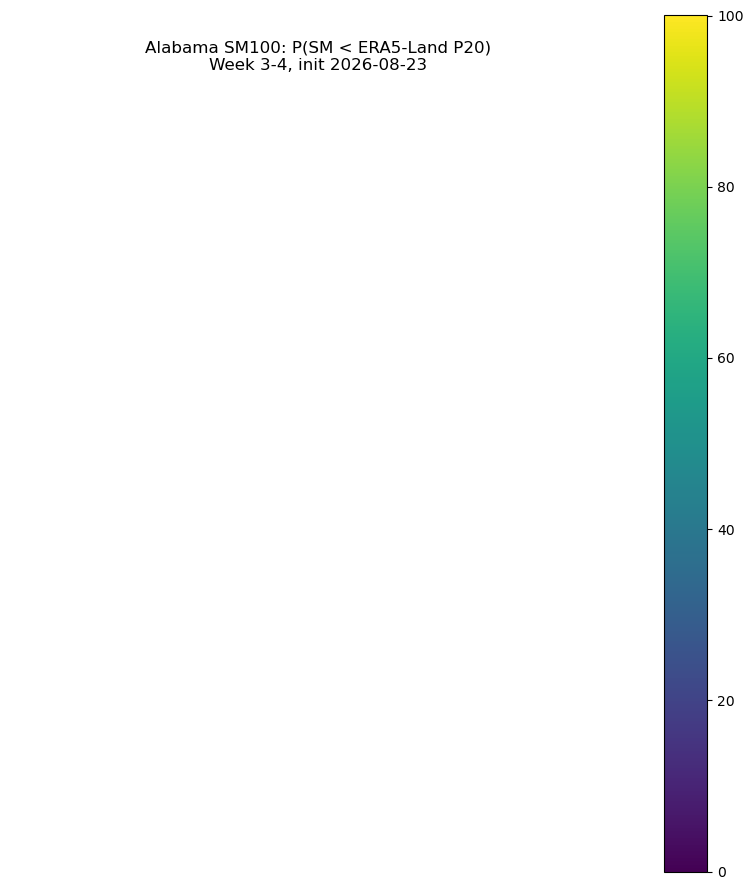

In [16]:

MAP_PERIOD = "Week 3-4"

plot_df = current_summary.loc[
    current_summary.period == MAP_PERIOD
].copy()

plot_gdf = counties.merge(
    plot_df,
    on=[
        "county_fips",
        "county_name"
    ],
    how="left"
)

fig, ax = plt.subplots(
    figsize=(8, 9)
)

plot_gdf.plot(
    column=100.0 * plot_gdf["prob_below_P20"],
    legend=True,
    vmin=0,
    vmax=100,
    ax=ax,
    edgecolor="black",
    linewidth=0.4
)

ax.set_title(
    f"Alabama {TARGET.upper()}: "
    f"P(SM < ERA5-Land P20)\n"
    f"{MAP_PERIOD}, init {MODEL_DATE:%Y-%m-%d}"
)

ax.set_axis_off()

plt.tight_layout()
plt.show()



## 14. Map cross-validated calibration improvement

This diagnostic maps:

\[
\Delta RMSE =
RMSE_{raw} - RMSE_{calibrated}
\]

Positive values indicate that calibration reduced RMSE.


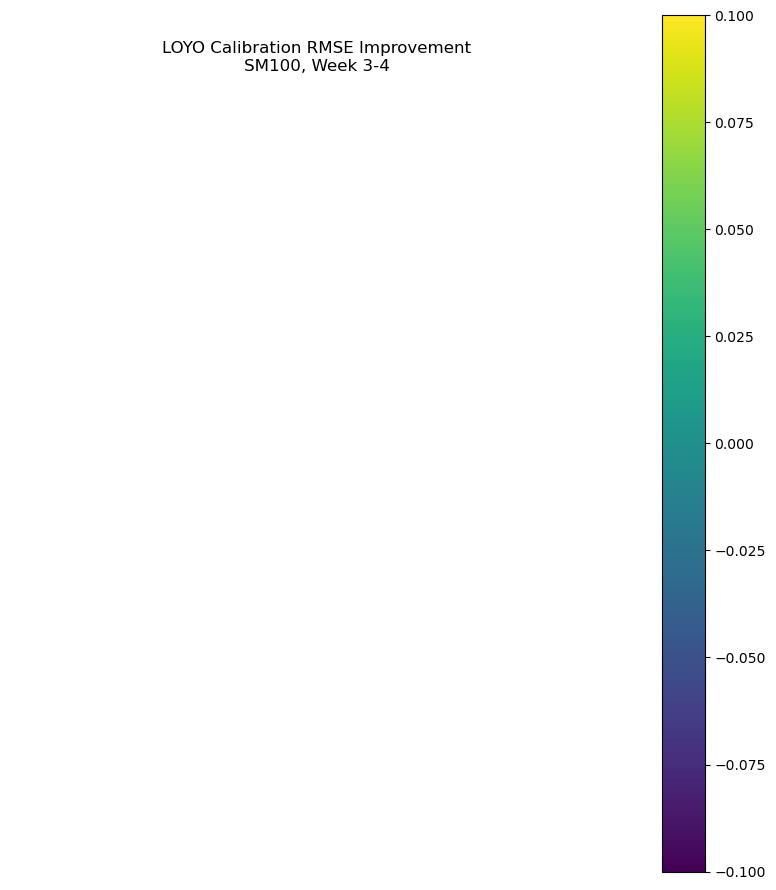

In [17]:

SKILL_PERIOD = "Week 3-4"

skill_df = cv_metrics.loc[
    cv_metrics.period == SKILL_PERIOD
].copy()

skill_df["RMSE_improvement"] = (
    skill_df["raw_RMSE"] -
    skill_df["calibrated_RMSE"]
)

skill_gdf = counties.merge(
    skill_df,
    on=[
        "county_fips",
        "county_name"
    ],
    how="left"
)

fig, ax = plt.subplots(
    figsize=(8, 9)
)

skill_gdf.plot(
    column="RMSE_improvement",
    legend=True,
    ax=ax,
    edgecolor="black",
    linewidth=0.4
)

ax.set_title(
    f"LOYO Calibration RMSE Improvement\n"
    f"{TARGET.upper()}, {SKILL_PERIOD}"
)

ax.set_axis_off()

plt.tight_layout()
plt.show()



## 15. Inspect an individual county

Example: Lee County.


In [18]:

COUNTY_TO_VIEW = "Lee"

county_result = current_summary.loc[
    current_summary.county_name ==
    COUNTY_TO_VIEW
].copy()

display(
    county_result[
        [
            "county_name",
            "period",
            "calibrated_ensemble_mean",
            "calibrated_p10",
            "calibrated_median",
            "calibrated_p90",
            "ERA5L_P20_threshold",
            "prob_below_P20",
            "n_native_grid_cells",
            "effective_grid_cells",
            "dominant_cell_fraction",
        ]
    ]
)


,county_name,period,calibrated_ensemble_mean,calibrated_p10,calibrated_median,calibrated_p90,ERA5L_P20_threshold,prob_below_P20,n_native_grid_cells,effective_grid_cells,dominant_cell_fraction
39,Lee,Week 1,0.333908,0.329418,0.330896,0.340376,0.313775,0.0,1,1.0,1.0



# How to interpret the county products

For each of Alabama's 67 counties, the pipeline produces:

- raw S2S ensemble mean;
- calibrated ensemble mean;
- calibrated P10/P50/P90;
- ERA5-Land P20 threshold;
- probability that calibrated soil moisture is below P20;
- LOYO bias, RMSE, and correlation;
- native-grid support diagnostics.

## Very important interpretation

A county-specific calibrated value does **not** mean ECMWF is resolving the county physically.

For many Alabama counties:

\[
\text{county size} \ll 1.5^\circ\ \text{S2S grid cell}
\]

so several adjacent counties can inherit essentially the same S2S forecast signal.  
The county differences after calibration primarily reflect county-specific ERA5-Land climatology
and bias mapping.

Therefore, for publication-quality county drought prediction, this experiment should be regarded
as a **statistically localized coarse-resolution S2S forecast**, not a dynamically resolved
county forecast.

## Recommended next scientific upgrades

1. Pool neighboring reforecast initialization dates to enlarge the calibration sample.
2. Verify probabilistic skill with CRPS, Brier score, reliability, and ROC/AUC.
3. Compare `sm20` and `sm100`.
4. Add county-level SCAN/USCRN/in-situ verification where station density permits.
5. Test statistical downscaling using ERA5-Land spatial predictors rather than simple interpolation.
6. Compare county forecasts against a simpler benchmark:
   - persistence;
   - ERA5-Land climatology;
   - uncalibrated ECMWF reforecast climatology.



## 16. Seasonal pooling of initialization dates

Everything above fits one calibration per (county, forecast period) using only the
20 historical reforecasts tied to a single calendar init date (`MODEL_DATE`'s month/day).
That gives each county/period calibration only ~20 training pairs (fewer once members are
collapsed to ensemble stats), which is thin for empirical quantile mapping.

Section 16 pools multiple ECMWF S2S initialization dates that fall in the same
meteorological season into one shared training sample, while still fitting a
separate calibration for every county and every forecast period. The result is the
folder structure:

```
County
 Week1   -> DJF, MAM, JJA, SON
 Week2   -> DJF, MAM, JJA, SON
 Week3-4 -> DJF, MAM, JJA, SON
 Week5-6 -> DJF, MAM, JJA, SON
```
**67 counties x 4 lead periods x 4 seasons = 1,072**; independent empirical-quantile-mapping
fits, each trained on all reforecast members from all pooled init dates x 20 hindcast
years that fall in that season, for that one county and that one lead period.

Seasons used (standard meteorological, not astronomical, seasons):

| Season | Months |
|---|---|
| DJF (winter) | Dec, Jan, Feb |
| MAM (spring) | Mar, Apr, May |
| JJA (summer) | Jun, Jul, Aug |
| SON (autumn) | Sep, Oct, Nov |

Meteorological seasons are used (not the Mar 20/Jun 21/... astronomical dates) because they
align with calendar months, which keeps grid-cell selection and file naming simple, and it's
the convention already implicit in ECMWF/S2S seasonal verification practice.

**Important cross-validation note:** ECMWF S2S is issued on Mondays and Thursdays, and the
on-the-fly reforecast for each of those dates covers the trailing 20 years. When multiple
init dates from the same season are pooled, the `hyear` column below is derived from the
true calendar year of each historical realization (not a relative offset), so leave-one-year-out
below still means "hold out every pooled realization from that one calendar year, across every
init date," which avoids leaking closely-correlated same-year information across folds.


In [19]:

# ============================================================
# SEASON DEFINITIONS
# ============================================================

SEASON_MONTHS = {
    "DJF": (12, 1, 2),
    "MAM": (3, 4, 5),
    "JJA": (6, 7, 8),
    "SON": (9, 10, 11),
}

SEASON_OF_MONTH = {
    m: s
    for s, months in SEASON_MONTHS.items()
    for m in months
}


def season_init_dates(season, reference_year, n_dates=6):
    """
    Representative ECMWF S2S initialization dates falling inside a
    meteorological season.

    The on-the-fly S2S reforecast system only has
    data for ODD calendar days of the month (1, 3, 5, ... 31), excluding
    Feb 29.
    """
    months = SEASON_MONTHS[season]

    if season == "DJF":
        start = pd.Timestamp(year=reference_year - 1, month=12, day=1)
        end = pd.Timestamp(year=reference_year, month=2, day=28)
    else:
        start = pd.Timestamp(year=reference_year, month=months[0], day=1)
        end = (
            pd.Timestamp(year=reference_year, month=months[-1], day=1)
            + pd.offsets.MonthEnd(1)
        )

    all_dates = pd.date_range(start, end, freq="D")
    all_dates = all_dates[all_dates.day % 2 == 1]
    all_dates = all_dates[~((all_dates.month == 2) & (all_dates.day == 29))]

    if len(all_dates) <= n_dates:
        return list(all_dates)

    idx = np.linspace(0, len(all_dates) - 1, n_dates).round().astype(int)
    idx = sorted(set(idx))
    return [all_dates[i] for i in idx]


### 16.1 Pull one pooled season's data (reforecasts + matching ERA5-Land obs)

This reuses the existing single-date functions (`download_s2s_reforecasts`,
`s2s_county_weekly`, `reforecast_to_dataframe`, `era5_county_verification`) once per
representative init date in the season, tags each result with `season` and `init_date`,
and concatenates. No changes to the calibration or LOYO functions are needed: they already
group only by `county_fips` and `period`, so handing them a longer, pooled `rf_df`/`obs_df`
is exactly what enlarges the training sample per county/period/season.


In [20]:

def build_season_pool(season, counties, n_dates=6, reference_year=None, target=TARGET):
    """
    Download + process every representative init date for one season and
    return pooled (rf_df, obs_df) tables tagged with season and init_date.
    """
    if reference_year is None:
        reference_year = pd.Timestamp(MODEL_DATE).year

    dates = season_init_dates(season, reference_year, n_dates=n_dates)
    print(f"[{season}] pooling {len(dates)} init dates:",
          [d.date().isoformat() for d in dates])

    rf_frames = []
    obs_frames = []

    for init_date in dates:
        init_date = pd.Timestamp(init_date)
        hindcast_years = list(range(init_date.year - 20, init_date.year))

        try:
            rf_files = download_s2s_reforecasts(init_date, target=target)
            rf_ens = load_s2s_ensemble(rf_files)

            (_, rf_weekly, _, _) = s2s_county_weekly(rf_ens, counties)

            rf_df_i = reforecast_to_dataframe(rf_weekly)
            rf_df_i["county_fips"] = rf_df_i["county_fips"].astype(str)
            rf_df_i = rf_df_i.loc[rf_df_i.hyear.isin(hindcast_years)].copy()
            rf_df_i["season"] = season
            rf_df_i["init_date"] = init_date.date().isoformat()

            print("Date: ", init_date)
            obs_df_i, _ = era5_county_verification(
                era5, counties, init_date, hindcast_years, target=target
            )
            obs_df_i["county_fips"] = obs_df_i["county_fips"].astype(str)
            obs_df_i["season"] = season
            obs_df_i["init_date"] = init_date.date().isoformat()

            rf_frames.append(rf_df_i)
            obs_frames.append(obs_df_i)

        except Exception as exc:
            # A missing reforecast for one issue date should not kill the
            # whole season pool -- log it and keep going.
            print(f"  ! skipped {init_date.date()}: {exc}")

    rf_pool = pd.concat(rf_frames, ignore_index=True)
    obs_pool = pd.concat(obs_frames, ignore_index=True)

    return rf_pool, obs_pool



### 16.2 Fit + validate every (county, period) calibration for one season, save in the requested tree

`calibrate_current_by_county` still needs a `rt_df` (the actual current 101-member
forecast to calibrate) — that only exists for the one true `MODEL_DATE`, not for every
pooled historical init date, so it is passed in separately. `loyo_cross_validation_by_county`
only needs the pooled `rf_df`/`obs_df`.


In [21]:

def run_season_calibration(season, rf_pool, obs_pool, rt_df, s2s_support, counties,
                            out_root):
    """
    Fit the county x period calibrations for one season from a pooled
    training sample, run LOYO validation, and save results into
    out_root/<county_name>/<period>/<season>/ as the requested tree.
    """
    cv_predictions, cv_metrics = loyo_cross_validation_by_county(rf_pool, obs_pool)

    current_summary, current_members = calibrate_current_by_county(
        rf_pool, obs_pool, rt_df, s2s_support
    )

    cv_metrics["season"] = season
    current_summary["season"] = season

    for county_name in sorted(current_summary["county_name"].unique()):
        for period in PERIODS:
            leaf = out_root / county_name / period.replace(" ", "") / season
            leaf.mkdir(parents=True, exist_ok=True)

            sub_summary = current_summary.loc[
                (current_summary.county_name == county_name)
                & (current_summary.period == period)
            ]
            sub_metrics = cv_metrics.loc[
                (cv_metrics.county_name == county_name)
                & (cv_metrics.period == period)
            ]
            sub_members = current_members.loc[
                (current_members.county_name == county_name)
                & (current_members.period == period)
            ]

            sub_summary.to_csv(leaf / "forecast_summary.csv", index=False)
            sub_metrics.to_csv(leaf / "loyo_metrics.csv", index=False)
            sub_members.to_csv(leaf / "calibrated_members.csv", index=False)

    return cv_predictions, cv_metrics, current_summary, current_members



### 16.3 Run the first-round, all-season, all-county, all-period pipeline

For the current real-time forecast (`MODEL_DATE`), only the season containing
`MODEL_DATE` needs a fresh `rt_df` — the other three seasons still get a full pooled
calibration + LOYO library built now, ready to score whichever real-time forecast is
issued while that season is active later.

**Download budget:** `N_INIT_DATES_PER_SEASON x 4 seasons x 20 hindcast years x 2`
(control + perturbed) reforecast files, plus one real-time pair. With the default of 6
init dates per season that is `6 x 4 x 20 x 2 = 960` reforecast files. Lower
`N_INIT_DATES_PER_SEASON` for a first smoke test (e.g. 2), then raise it once the
pipeline and credentials are confirmed working end to end.


In [ ]:

N_INIT_DATES_PER_SEASON = 6 # Assign value back to 6 when test for 2 is successful.

SEASON_LIBRARY_ROOT = OUT / f"AL_county_{COUNTY_TAG}_{TARGET}_season_library"
SEASON_LIBRARY_ROOT.mkdir(parents=True, exist_ok=True)

CURRENT_SEASON = SEASON_OF_MONTH[pd.Timestamp(MODEL_DATE).month]
print(MODEL_DATE, "falls in season:", CURRENT_SEASON)

all_cv_metrics = []
all_current_summary = []

for season in ["DJF", "MAM", "JJA", "SON"]:
    print(f"\n=== Building season {season} ===")

    rf_pool, obs_pool = build_season_pool(
        season, counties, n_dates=N_INIT_DATES_PER_SEASON
    )

    rf_pool.to_csv(
        SEASON_LIBRARY_ROOT / f"pooled_reforecasts_{season}.csv", index=False
    )
    obs_pool.to_csv(
        SEASON_LIBRARY_ROOT / f"pooled_obs_{season}.csv", index=False
    )

    if season == CURRENT_SEASON:
        # Use the already-downloaded actual current forecast (from section 12)
        # so this season's calibration is applied to a real issued forecast.
        season_rt_df = rt_df
    else:
        # No live forecast exists for the other seasons yet; use the most
        # recent pooled init date in that season purely so
        # calibrate_current_by_county has a rt_df shaped table to run
        # against for library-building purposes. Replace with a real rt_df
        # once a forecast is actually issued in that season.
        placeholder_date = pd.Timestamp(rf_pool["init_date"].max())
        placeholder_files = download_s2s_realtime(placeholder_date, target=TARGET)
        placeholder_ens = load_s2s_ensemble(placeholder_files)
        (_, placeholder_weekly, _, _) = s2s_county_weekly(placeholder_ens, counties)
        season_rt_df = realtime_to_dataframe(placeholder_weekly)
        season_rt_df["county_fips"] = season_rt_df["county_fips"].astype(str)

    print(f"{season}: rf_pool rows={len(rf_pool)}, obs_pool rows={len(obs_pool)}")
    print(f"{season}: rf hyears={sorted(rf_pool.hyear.unique())[:5]}...")
    print(f"{season}: obs hyears={sorted(obs_pool.hyear.unique())[:5]}...")

    cv_predictions, cv_metrics, current_summary, current_members = (
        run_season_calibration(
            season, rf_pool, obs_pool, season_rt_df, s2s_support, counties,
            SEASON_LIBRARY_ROOT
        )
    )

    all_cv_metrics.append(cv_metrics)
    all_current_summary.append(current_summary)

all_cv_metrics = pd.concat(all_cv_metrics, ignore_index=True)
all_current_summary = pd.concat(all_current_summary, ignore_index=True)

all_cv_metrics.to_csv(
    SEASON_LIBRARY_ROOT / "ALL_county_period_season_LOYO_metrics.csv", index=False
)
all_current_summary.to_csv(
    SEASON_LIBRARY_ROOT / "ALL_county_period_season_forecast_summary.csv", index=False
)

print("\nSeason library complete:", SEASON_LIBRARY_ROOT)
print("Rows in combined LOYO metrics table:", len(all_cv_metrics))


2026-08-23 00:00:00 falls in season: JJA

=== Building season DJF ===
[DJF] pooling 6 init dates: ['2025-12-01', '2025-12-19', '2026-01-05', '2026-01-23', '2026-02-09', '2026-02-27']
Date:  2025-12-01 00:00:00
Calculating ERA5-Land county overlap weights...
ERA5-Land county verification completed: 2005
ERA5-Land county verification completed: 2006
ERA5-Land county verification completed: 2007
ERA5-Land county verification completed: 2008
ERA5-Land county verification completed: 2009
ERA5-Land county verification completed: 2010
ERA5-Land county verification completed: 2011
ERA5-Land county verification completed: 2012
ERA5-Land county verification completed: 2013
ERA5-Land county verification completed: 2014
ERA5-Land county verification completed: 2015
ERA5-Land county verification completed: 2016
ERA5-Land county verification completed: 2017
ERA5-Land county verification completed: 2018
ERA5-Land county verification completed: 2019
ERA5-Land county verification completed: 2020
ERA5-L


### 16.4 Difference of Section 16

- **Sample size per calibration:** grows from ~20 hindcast years to roughly
  `N_INIT_DATES_PER_SEASON x 20` hindcast realizations per county/period/season
  (minus any skipped/missing reforecast dates).
- **Granularity preserved:** calibration is still fit separately for each of the 67
  counties and each of the 4 lead periods — pooling only happens within a season, across
  init dates, never across counties, periods, or seasons.
- **Reusability:** because a full season's library is built once, any real-time forecast
  issued later in that same season can be calibrated by looking up its
  `county / period / season` leaf directory rather than re-running LOYO from scratch.
- **Next validation step:** compare `ALL_county_period_season_LOYO_metrics.csv` against the
  single-date `cv_metrics` from section 12 (same county/period) to confirm the pooled
  version actually reduces LOYO RMSE / improves reliability before treating it as the
  production calibration.
